# Regression Analysis and OLS Model Summary

### What is Regression Analysis?

- **Regression analysis** is a statistical method used to understand the relationship between one or more independent variables (features) and a dependent variable (the value we want to explain or predict).
- It helps estimate how the target changes when the input features change.
- In this notebook, we first compare a known population regression line with a line estimated from generated data, then analyse an advertising dataset using Ordinary Least Squares (OLS).

### What is Ordinary Least Squares (OLS)?

- **OLS** is a method used to estimate the coefficients of a linear regression model.
- It chooses the coefficients that minimize the **sum of squared residuals**.
- A residual is the difference between an actual value and the value predicted by the model.
- Statsmodels provides an OLS summary containing coefficient estimates, model-fit statistics, significance tests, and diagnostic information.

For a model with multiple input features, the general equation is:

$$
\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \cdots + \beta_p x_p
$$

Where $\beta_0$ is the intercept, $\beta_1,\ldots,\beta_p$ are feature coefficients, and $\hat{y}$ is the predicted target value.

**Notebook roadmap:** compare a known and estimated line → fit an OLS model to advertising data → understand every important part of `model.summary()`.


In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.linear_model import LinearRegression

### Compare the Population Line with the Estimated Regression Line

The first example generates data from a known relationship:

$$
y = 2x - 5 + \text{random noise}
$$

- The **population line** is the original relationship used to generate the data: slope $=2$ and intercept $=-5$.
- The **estimated regression line** is learned from the generated sample using `LinearRegression`.
- Random noise makes the points differ from the population line, so the estimated coefficients may not be exactly 2 and -5.
- The plot compares the generated data points, the known population line, and the estimated line.


In [2]:
# generate the data 
x = 10 * np.random.rand(50)
y = 2 * x - 5 + np.random.rand(50) * 4

In [3]:
# fit an LinearRegression model 
x = x.reshape(-1,1)
model = LinearRegression()
model.fit(x, y)

LinearRegression()

In [4]:
# predicted  values 
y_pred = model.predict(x)

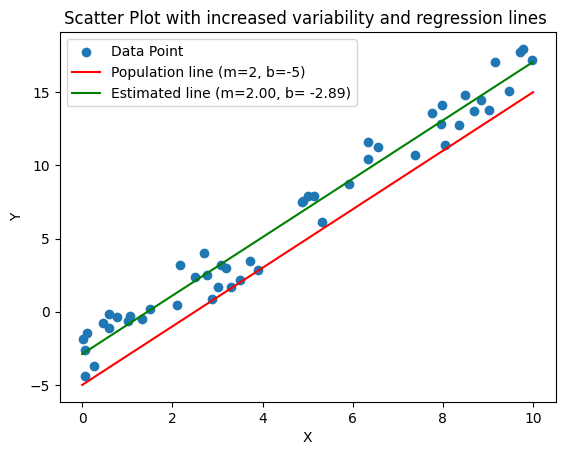

In [5]:
# plot the scatter plot and regression lines 
plt.scatter(x,y, label = 'Data Point')
plt.xlabel('X')
plt.ylabel('Y')

plt.title('Scatter Plot with increased variability and regression lines ')

# plot the acutal population line 
x_line = np.linspace(0, 10, 100)
y_actual = 2 * x_line - 5
plt.plot(x_line, y_actual, 'r', label= "Population line (m=2, b=-5)")

# plot the estimated regression line
y_estimated = model.coef_[0] * x_line + model.intercept_
plt.plot(x_line, y_estimated, 'g', label=f'Estimated line (m={model.coef_[0]:.2f}, b= {model.intercept_:.2f})')


plt.legend()

### Fit an OLS Model on the Advertising Dataset

This section uses the Advertising dataset to study how advertising budgets relate to product sales.

- **Dependent variable (target):** `Sales`
- **Independent variables (features):** `TV`, `Radio`, and `Newspaper`
- `sm.add_constant(X)` adds a constant column so the model can estimate an intercept.
- `sm.OLS(y, X).fit()` fits the Ordinary Least Squares regression model.
- `model.summary()` prints a detailed statistical report about the fitted model.

The summary is not just a score. It contains several groups of information, explained below.


In [6]:
import pandas as pd
import statsmodels.api as sm
# Load the dataset
url = "https://raw.githubusercontent.com/justmarkham/scikit-learn-videos/master/data/Advertising.csv"
data = pd.read_csv(url, index_col=0)
# Define the independent variables (add a constant for the intercept)
X = data[[ 'TV', 'Radio', 'Newspaper' ]]
X = sm.add_constant(X)

# Define the dependent variable
y = data[ 'Sales' ]
# Fit the model using the independent and dependent variables
model = sm.OLS(y, X).fit()
# Print the summary of the model
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     570.3
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           1.58e-96
Time:                        21:43:25   Log-Likelihood:                -386.18
No. Observations:                 200   AIC:                             780.4
Df Residuals:                     196   BIC:                             793.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.9389      0.312      9.422      0.0

### How to Read the OLS Model Summary

The output of `model.summary()` is divided into sections. The values below refer to the summary produced by this notebook's Advertising dataset.

#### 1. Model information and overall fit

| Summary field | What it means | How to interpret this notebook's result |
|---|---|---|
| **Dep. Variable** | The dependent variable the model is explaining or predicting. | `Sales` is the target. |
| **Model** | The statistical model used. | `OLS` means Ordinary Least Squares. |
| **Method** | The method used to estimate the coefficients. | `Least Squares` chooses coefficients that minimize squared residuals. |
| **No. Observations** | Number of rows used to fit the model. | `200` observations were used. |
| **Df Model** | Number of explanatory variables, excluding the intercept. | `3`: TV, Radio, and Newspaper. |
| **Df Residuals** | Residual degrees of freedom; observations minus the number of estimated parameters. | `196` (200 observations minus 4 estimated parameters, including the intercept). |
| **R-squared** | Proportion of variation in the target explained by the model, on the training data used to fit it. | `0.897` means the model explains about 89.7% of the variation in Sales in this dataset. |
| **Adj. R-squared** | R-squared adjusted for the number of predictors and observations. It penalizes adding predictors that do not improve the model enough. | `0.896`, very close to R-squared. |
| **F-statistic** | Tests whether the model with its predictors provides a better fit than an intercept-only model. | `570.3`, a large test statistic. |
| **Prob (F-statistic)** | P-value for the overall F-test. | `1.58e-96`, very small; the predictors are jointly statistically associated with Sales under the model's assumptions. |
| **Log-Likelihood** | A measure based on the likelihood of the fitted model; it is mainly useful when comparing models fitted to the same response data. | `-386.18`. By itself, it is not an intuitive accuracy score. |
| **AIC** | Akaike Information Criterion; balances model fit with a penalty for model complexity. | `780.4`. Lower is preferred when comparing suitable models fitted to the same data. |
| **BIC** | Bayesian Information Criterion; similar to AIC but applies a stronger complexity penalty in many settings. | `793.6`. Lower is preferred when comparing suitable models fitted to the same data. |
| **Covariance Type** | The method used to estimate coefficient covariance and standard errors. | `nonrobust` means the usual OLS standard errors are used, relying on the standard error assumptions. |

**Important:** R-squared is not the percentage of predictions that are correct. It describes the proportion of target variation explained by the fitted model.

#### 2. Coefficient table

The coefficient table explains the estimated relationship between each feature and Sales.

| Column | Meaning |
|---|---|
| **coef** | Estimated coefficient. It represents the expected change in the target for a one-unit increase in that feature, holding the other included features constant. |
| **std err** | Standard error of the coefficient estimate; it measures its estimated uncertainty. |
| **t** | t-statistic, calculated approximately as `coef / std err`. It tests whether the coefficient is different from zero. |
| **P>\|t\|** | Two-sided p-value for the test that the coefficient is zero. A small p-value is evidence against that null hypothesis, assuming the model conditions hold. |
| **[0.025, 0.975]** | Lower and upper endpoints of the 95% confidence interval for the coefficient. |

**Interpret the coefficients from this output:**

- **const = 2.9389:** The estimated Sales value when TV, Radio, and Newspaper budgets are all zero. This is the model's intercept.
- **TV = 0.0458:** Holding Radio and Newspaper constant, a one-unit increase in TV budget is associated with an estimated 0.0458-unit increase in Sales.
- **Radio = 0.1885:** Holding TV and Newspaper constant, a one-unit increase in Radio budget is associated with an estimated 0.1885-unit increase in Sales.
- **Newspaper = -0.0010:** Holding TV and Radio constant, the estimated association is very close to zero and slightly negative.

The p-values in this output are:

- **const: 0.000** — displayed rounded; it does not mean the p-value is exactly zero.
- **TV: 0.000** — displayed rounded; statistically significant at the conventional 0.05 level.
- **Radio: 0.000** — displayed rounded; statistically significant at the conventional 0.05 level.
- **Newspaper: 0.860** — not statistically significant at the conventional 0.05 level in this fitted model.

The 95% confidence interval for Newspaper is approximately `[-0.013, 0.011]`. Because this interval includes zero, the data do not provide strong evidence that its coefficient differs from zero after accounting for the other included features.

**Remember:** Statistical significance does not prove causation or automatically mean a feature is practically important. Coefficients are interpreted while holding the other included predictors constant.

#### 3. Model diagnostic statistics

These statistics provide information about the residuals and possible modelling issues.

| Summary field | What it checks | Interpretation of this output |
|---|---|---|
| **Omnibus** | A combined test of residual normality, using skewness and kurtosis. | `60.414`; the associated p-value is `0.000`, suggesting residuals depart from normality. |
| **Prob(Omnibus)** | P-value for the Omnibus test. | Very small; evidence against normally distributed residuals. |
| **Jarque-Bera (JB)** | Another test of residual normality based on skewness and kurtosis. | `151.241`. |
| **Prob(JB)** | P-value for the Jarque-Bera test. | `1.44e-33`, very small; evidence against residual normality. |
| **Skew** | Measures residual asymmetry. Zero indicates symmetry. | `-1.327` indicates negative (left) skew. |
| **Kurtosis** | Describes tail weight and peakedness; a normal distribution has kurtosis around 3 in this convention. | `6.332` indicates heavier tails / greater kurtosis than a normal distribution. |
| **Durbin-Watson** | Checks for first-order autocorrelation in residuals. A value around 2 suggests little first-order autocorrelation. | `2.084`, close to 2. |
| **Cond. No.** | Condition number of the design matrix; a large value can indicate scaling problems or multicollinearity. | `454`; investigate feature scales and relationships if concerned. |

**Important:** These diagnostic statistics are signals to investigate, not automatic proof that a model is good or bad. Residual plots and knowledge of the data are also important.

#### 4. Notes at the bottom

`Standard Errors assume that the covariance matrix of the errors is correctly specified.`

This means the reported standard errors, t-statistics, p-values, and confidence intervals rely on the covariance assumptions used by the model. The summary reports `Covariance Type: nonrobust`, so it uses the conventional non-robust covariance estimator.

If assumptions such as constant error variance are not reasonable, consider residual diagnostics and an appropriate robust standard-error method. Robust standard errors change inference estimates; they do not automatically fix a poorly specified model.

#### 5. Main interpretation of this model

- The model has an R-squared of `0.897` and an adjusted R-squared of `0.896`.
- The overall F-test has a very small p-value, indicating that the included predictors are jointly associated with Sales under the model assumptions.
- TV and Radio have positive, statistically significant coefficients in this fitted model.
- Newspaper has a p-value of `0.860`, so its coefficient is not statistically significant at the conventional 0.05 level after accounting for TV and Radio.
- The residual normality tests indicate departures from normality, so diagnostic checks matter before relying on inference.

These are associations in this dataset; they should not be interpreted as proof that changing an advertising budget will cause the stated change in Sales.


### Key Takeaways

1. Regression analysis studies the relationship between input features and a numerical target.
2. OLS estimates linear-model coefficients by minimizing the sum of squared residuals.
3. R-squared and adjusted R-squared describe model fit, while the F-test evaluates the predictors jointly.
4. The coefficient table explains estimated feature relationships, their standard errors, t-statistics, p-values, and confidence intervals.
5. A small p-value is evidence against a zero coefficient under the model assumptions; it does not prove causation.
6. Residual diagnostics help identify departures from assumptions that can affect statistical inference.
7. Compare AIC and BIC only across suitable models fitted to the same response data; lower values are generally preferred.
